In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [2]:
image = cv2.imread("sar_3.jpg")
if image is None:
    raise FileNotFoundError("Поместите sar_3.jpg рядом с ноутбуком")

rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
filtered = cv2.medianBlur(gray, 3)


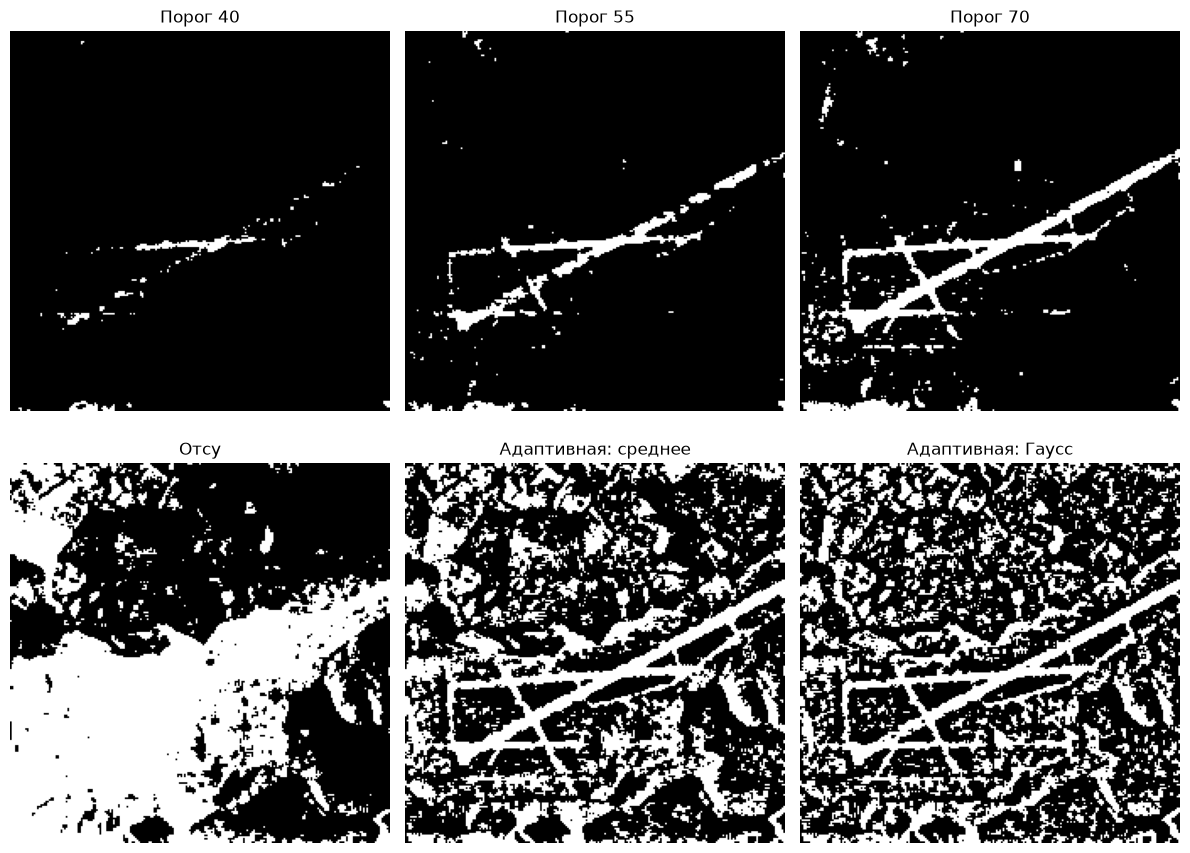

Порог Отсу: 128


In [7]:
masks = {}

for threshold in [40, 55, 70]:
    _, masks[f"Порог {threshold}"] = cv2.threshold(
        filtered, threshold, 255, cv2.THRESH_BINARY_INV
    )

otsu_threshold, masks["Отсу"] = cv2.threshold(
    filtered, 0, 255,
    cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)

masks["Адаптивная: среднее"] = cv2.adaptiveThreshold(
    filtered, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY_INV,
    31, 7
)

masks["Адаптивная: Гаусс"] = cv2.adaptiveThreshold(
    filtered, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    31, 7
)

fig, axes = plt.subplots(2, 3, figsize=(12, 9))

for ax, (name, mask) in zip(axes.ravel(), masks.items()):
    ax.imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Порог Отсу: {otsu_threshold:.0f}")

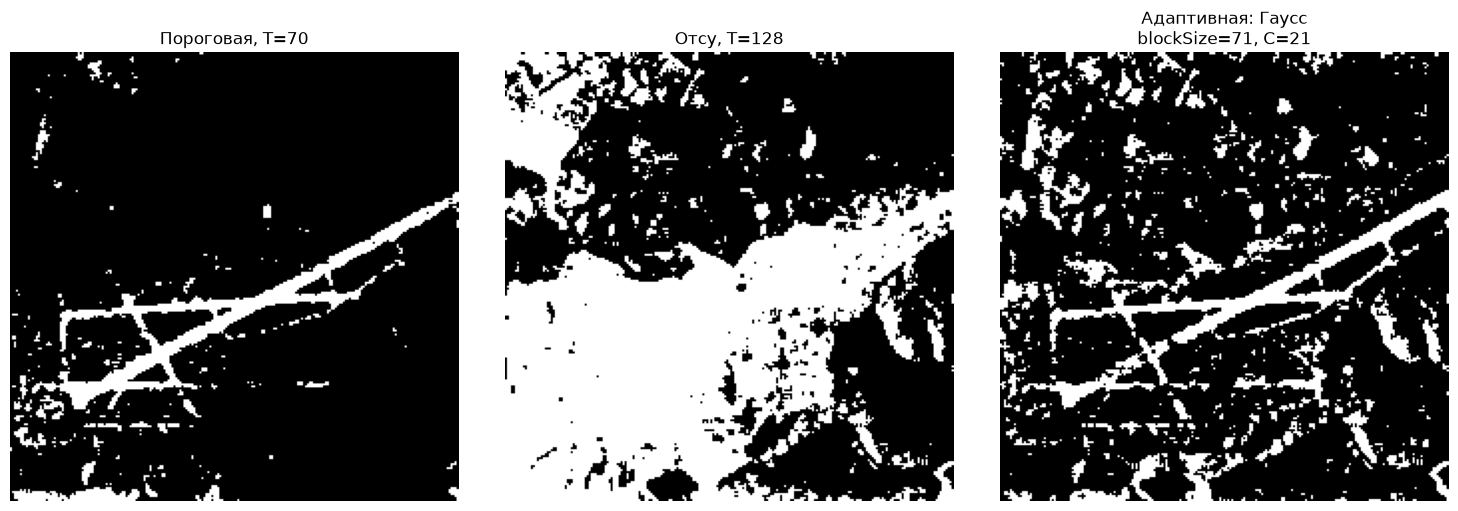

In [11]:
T = 70
_, binary_fixed = cv2.threshold(
    filtered, T, 255, cv2.THRESH_BINARY_INV
)


T_otsu, binary_otsu = cv2.threshold(
    filtered, 0, 255,
    cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)


binary_adaptive = cv2.adaptiveThreshold(
    filtered,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    blockSize=71,
    C=21
)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(binary_fixed, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Пороговая, T={T}")
axes[0].axis("off")

axes[1].imshow(binary_otsu, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Отсу, T={T_otsu:.0f}")
axes[1].axis("off")

axes[2].imshow(binary_adaptive, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Адаптивная: Гаусс\nblockSize=71, C=21")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [8]:
binary = masks["Порог 70"]

kernel = np.ones((3, 3), dtype=np.uint8)
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

count, labels, stats, _ = cv2.connectedComponentsWithStats(
    closed, connectivity=8
)

if count <= 1:
    raise ValueError("Не найдены объекты после бинаризации")

largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
road_mask = np.uint8(labels == largest_label) * 255

Среди рассмотренных вариантов лучший визуальный результат выделения дорожного участка показала пороговая бинаризация со значением T = 70 после медианной фильтрации. Она сохраняет основную дорожную полосу при относительно небольшом количестве фоновых помех. Адаптивная гауссова бинаризация с параметрами blockSize = 71 и C = 21 также выделяет дорожную полосу, однако сохраняет больше посторонних объектов. Метод Отсу с автоматически выбранным порогом T = 128 показал наименее подходящий результат для данной задачи: дорожная полоса сливается.

Найдено отрезков: 5
Самый длинный отрезок: 114.06 пикселей
Координаты: (123, 122) — (224, 69)


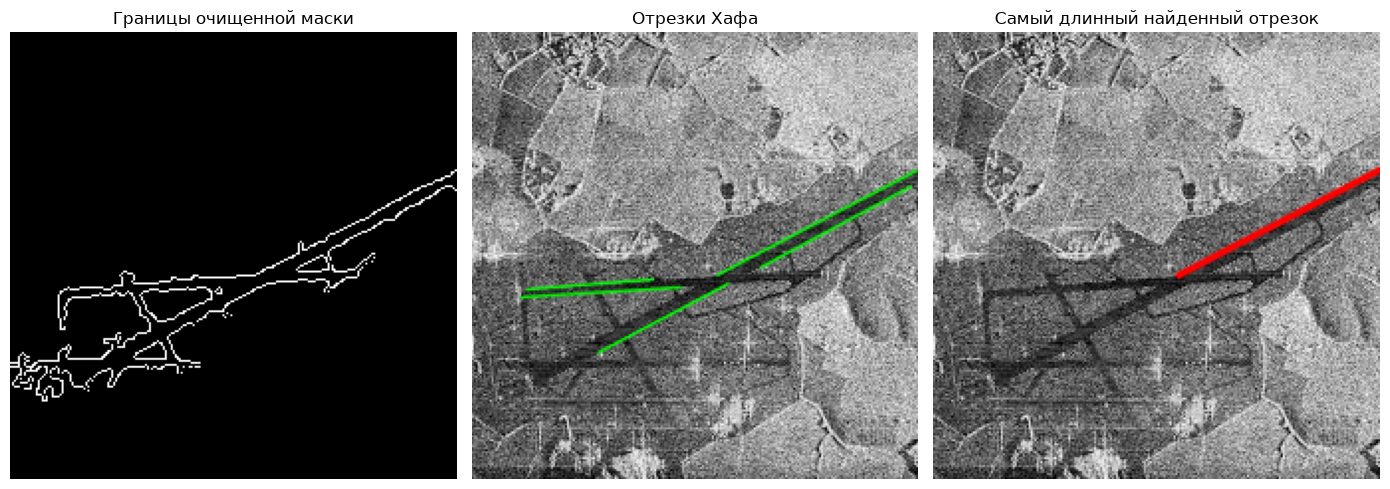

In [9]:
edges = cv2.Canny(road_mask, 50, 150)

lines = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi / 360,
    threshold=20,
    minLineLength=60,
    maxLineGap=8
)

all_lines = rgb.copy()
longest_line = rgb.copy()

if lines is not None and lines.size > 0:
    segments = np.asarray(lines).reshape(-1, 4)

    lengths = np.hypot(
        segments[:, 2] - segments[:, 0],
        segments[:, 3] - segments[:, 1]
    )

    for segment in segments:
        x1, y1, x2, y2 = map(int, segment)
        cv2.line(
            all_lines, (x1, y1), (x2, y2),
            (0, 255, 0), 1, cv2.LINE_AA
        )

    index = int(np.argmax(lengths))
    x1, y1, x2, y2 = map(int, segments[index])

    cv2.line(
        longest_line, (x1, y1), (x2, y2),
        (255, 0, 0), 2, cv2.LINE_AA
    )

    print(f"Найдено отрезков: {len(segments)}")
    print(f"Самый длинный отрезок: {lengths[index]:.2f} пикселей")
    print(f"Координаты: ({x1}, {y1}) — ({x2}, {y2})")
else:
    print("Отрезки не найдены")

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, img, title in zip(
    axes,
    [edges, all_lines, longest_line],
    [
        "Границы очищенной маски",
        "Отрезки Хафа",
        "Самый длинный найденный отрезок"
    ]
):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


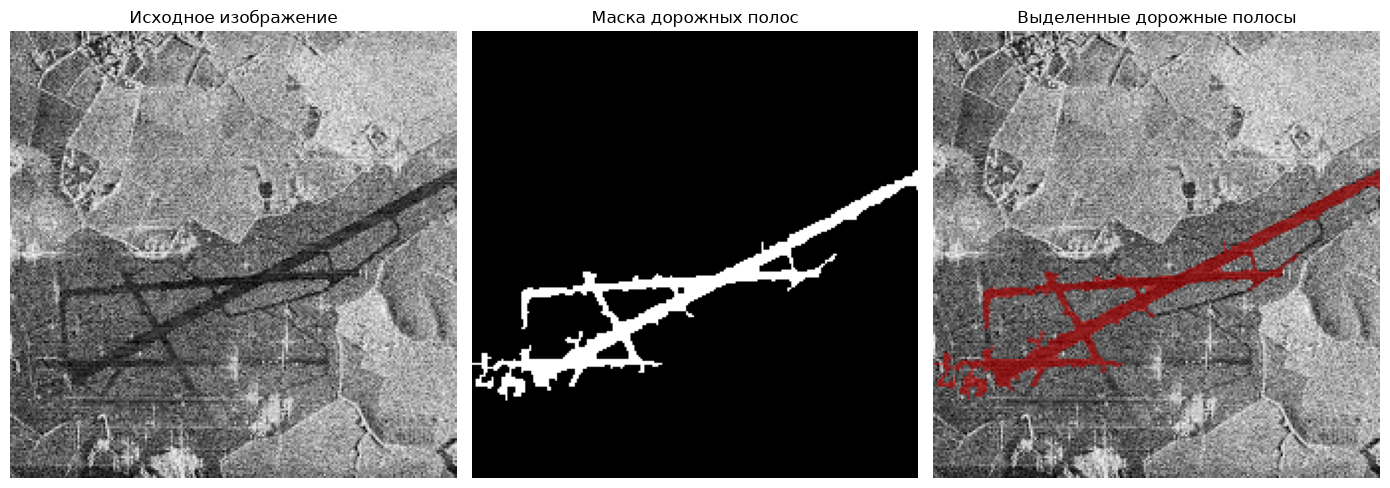

In [10]:
overlay = rgb.copy()
pixels = road_mask > 0

overlay[pixels] = (
    0.55 * rgb[pixels] + 0.45 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, img, title in zip(
    axes,
    [rgb, road_mask, overlay],
    [
        "Исходное изображение",
        "Маска дорожных полос",
        "Выделенные дорожные полосы"
    ]
):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()